In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv("./build1/pixel_hit_histogram.csv")
pixel_pitch = 0.055  # mm, must match what was used in the C++ code

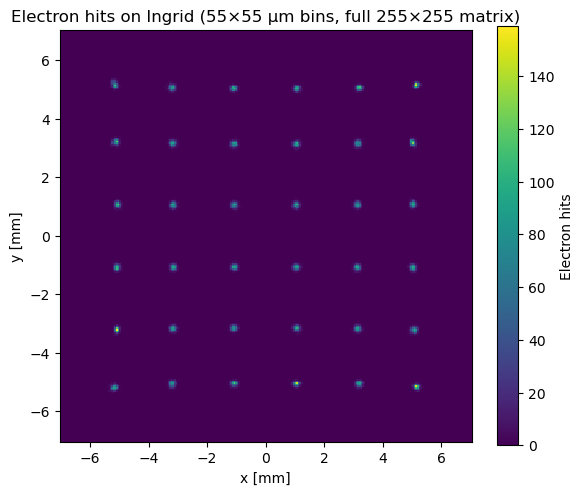

In [18]:
pixel_pitch = 0.055   # mm (55 um)
n_pixels = 256        # full Ingrid matrix with pixel indices 0..255
half_range = n_pixels * pixel_pitch / 2.0  # 7.04 mm

# Fixed bin edges spanning the whole pixel matrix, center pixel at (0,0)
edges = -half_range + pixel_pitch * np.arange(n_pixels + 1)

# Sanity check: flag any hits that fall outside the physical pixel matrix
out_of_range = df[(df.x_center_mm.abs() > half_range) |
                   (df.y_center_mm.abs() > half_range)]
if len(out_of_range):
    print(f"Warning: {len(out_of_range)} bin(s) fall outside the "
          f"±{half_range:.4f} mm pixel matrix and will be dropped.")

grid, x_edges, y_edges = np.histogram2d(
    df.x_center_mm, df.y_center_mm,
    bins=[edges, edges],
    weights=df["count"],
)

# --- Plot as a heatmap ---
fig, ax = plt.subplots(figsize=(6, 5))
mesh = ax.pcolormesh(x_edges, y_edges, grid.T, cmap="viridis", shading="flat")
cbar = fig.colorbar(mesh, ax=ax, label="Electron hits")
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_title("Electron hits on Ingrid (55×55 µm bins, full 255×255 matrix)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

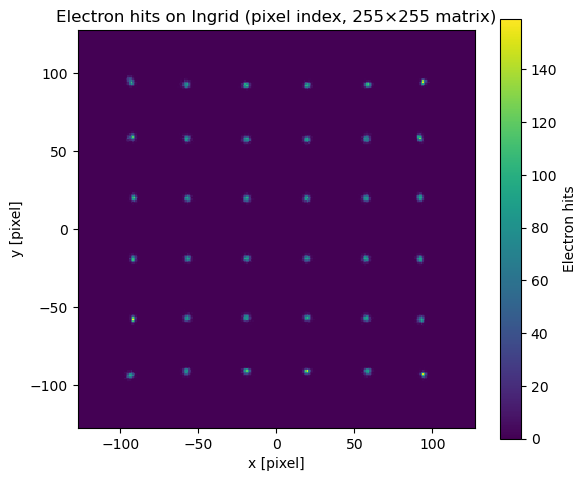

In [20]:
n_half = (n_pixels - 1) // 2  # 127, since center pixel is index 0

# Pixel-index edges, centered on pixel (0,0)
pix_edges = np.arange(-n_half - 0.5, n_half + 1.5, 1)

# Convert physical centers to pixel indices (should already be integers,
# this just guards against floating-point rounding)
px = np.round(df.x_center_mm / pixel_pitch).astype(int)
py = np.round(df.y_center_mm / pixel_pitch).astype(int)

out_of_range_px = df[(px.abs() > n_half) | (py.abs() > n_half)]
if len(out_of_range_px):
    print(f"Warning: {len(out_of_range_px)} bin(s) fall outside "
          f"pixel indices ±{n_half} and will be dropped.")

grid_px, x_edges_px, y_edges_px = np.histogram2d(
    px, py, bins=[pix_edges, pix_edges], weights=df["count"],
)

fig, ax = plt.subplots(figsize=(6, 5))
mesh = ax.pcolormesh(x_edges_px, y_edges_px, grid_px.T, cmap="viridis", shading="flat")
cbar = fig.colorbar(mesh, ax=ax, label="Electron hits")
ax.set_xlabel("x [pixel]")
ax.set_ylabel("y [pixel]")
ax.set_title("Electron hits on Ingrid (pixel index, 255×255 matrix)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [10]:
from collections import deque

df = pd.read_csv("./build1/pixel_hit_histogram.csv")
df = df[df["count"] > 0].copy()

# Cluster occupied bins in (ix, iy) space using 8-connectivity
occupied = {(int(r.ix), int(r.iy)) for _, r in df.iterrows()}
visited = set()
clusters = []

for start in occupied:
    if start in visited:
        continue
    stack = [start]
    visited.add(start)
    members = []
    while stack:
        cx, cy = stack.pop()
        members.append((cx, cy))
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                if dx == 0 and dy == 0:
                    continue
                nb = (cx + dx, cy + dy)
                if nb in occupied and nb not in visited:
                    visited.add(nb)
                    stack.append(nb)
    clusters.append(members)

coord_to_row = {(int(r.ix), int(r.iy)): r for _, r in df.iterrows()}
cluster_rows = []
for cluster_id, members in enumerate(clusters, start=1):
    rows = [coord_to_row[m] for m in members]
    cluster_df = pd.DataFrame(rows)
    weights = cluster_df["count"].astype(float)
    x = cluster_df["x_center_mm"].astype(float)
    y = cluster_df["y_center_mm"].astype(float)
    mean_x = np.average(x, weights=weights)
    mean_y = np.average(y, weights=weights)
    sigma_x = np.sqrt(np.average((x - mean_x) ** 2, weights=weights))
    sigma_y = np.sqrt(np.average((y - mean_y) ** 2, weights=weights))
    cluster_rows.append({
        "cluster_id": cluster_id,
        "n_bins": len(rows),
        "total_count": int(weights.sum()),
        "mean_x_mm": mean_x,
        "mean_y_mm": mean_y,
        "sigma_x_mm": sigma_x,
        "sigma_y_mm": sigma_y,
    })

cluster_summary = pd.DataFrame(cluster_rows).sort_values("total_count", ascending=False)
cluster_summary_filtered = cluster_summary[cluster_summary["total_count"] > 100]  # Ensure total_count is int

cluster_summary.to_csv("./build1/cluster_summary.csv", index=False)
print(f"Found {len(cluster_summary_filtered)} clusters")
print(cluster_summary_filtered.to_string(index=False))

Found 36 clusters
 cluster_id  n_bins  total_count  mean_x_mm  mean_y_mm  sigma_x_mm  sigma_y_mm
          1      46         1000   5.053720   1.087560    0.060809    0.072540
          3      44         1000   5.043215   3.192575    0.054415    0.074844
          4      48         1000   5.051850  -1.080430    0.062106    0.074153
          5      50         1000  -5.148505   5.181375    0.066464    0.084481
          7      45         1000  -5.048185   1.077715    0.057865    0.071234
          9      52         1000  -5.110500   3.217985    0.073667    0.070414
          8      50         1000  -5.069030  -1.074050    0.061252    0.071751
         11      51         1000  -3.141995  -1.064425    0.068970    0.071495
         10      53         1000  -3.152060   1.060225    0.067896    0.072362
         36      41         1000  -5.069195  -3.199635    0.046998    0.067999
         35      51         1000   5.087710  -3.214375    0.068216    0.071062
         15      53         1000  

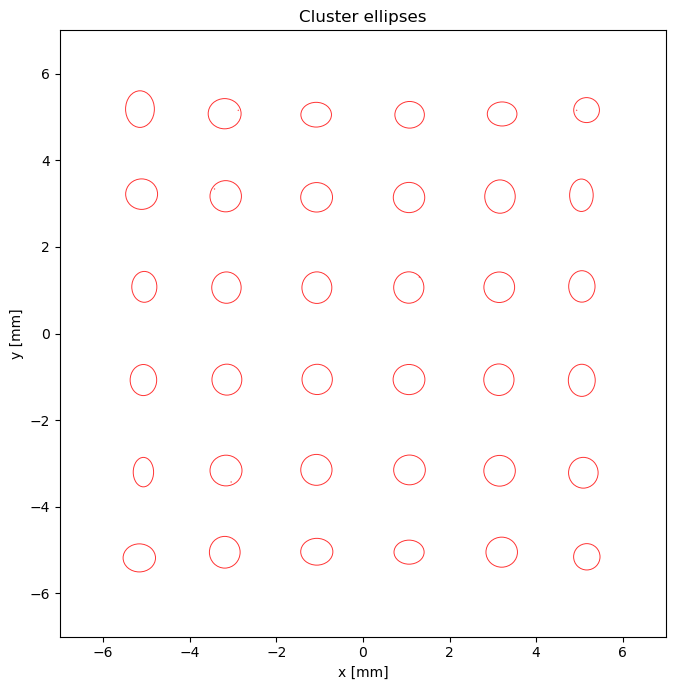

In [17]:
from matplotlib.patches import Ellipse

# Use the cluster summary table directly
cluster_summary = pd.read_csv("./build1/cluster_summary.csv")

fig, ax = plt.subplots(figsize=(7, 7))

for _, row in cluster_summary.iterrows():
    mean_x = row['mean_x_mm']
    mean_y = row['mean_y_mm']
    sigma_x = row['sigma_x_mm']
    sigma_y = row['sigma_y_mm']

    # ax.scatter(mean_x, mean_y, color='red', s=12)
    ellipse = Ellipse(
        (mean_x, mean_y),
        width=max(10 * sigma_x, 0.01),
        height=max(10 * sigma_y, 0.01),
        angle=0,
        facecolor='none',
        edgecolor='red',
        linewidth=0.7,
        alpha=0.8,
    )
    ax.add_patch(ellipse)

ax.set_xlim(-7, 7)
ax.set_ylim(-7, 7)
ax.set_xlabel('x [mm]')
ax.set_ylabel('y [mm]')
ax.set_title('Cluster ellipses')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()